# Cadena del maíz: campo, central de abasto, tortilla y Gruma (2018–2025)

## 1. Pregunta y decisiones

**Pregunta:** cuando el maíz se encareció entre 2020 y 2023, ¿en qué eslabón de la cadena se quedó el golpe y quién recibió la baja posterior?

Decisiones de diseño:

- Eslabones: productor (precio medio rural, DGSIAP), mayorista (cinco centrales de abasto, SNIIM) y tortilla al consumidor (PROFECO, tortillerías). Gruma (`GRUMAB.MX`) se analiza aparte porque su rendimiento es bursátil y no un precio por kilo.
- Periodo: 2018–2025, los años en que coinciden las tres fuentes de precios.
- Fase de subida: 2020 hasta el pico (2022 o 2023, se muestran ambos). Fase de bajada: del pico a 2025.
- Descriptivo: no se estima causalidad ni se separan costos de flete, acopio o margen.

## 2. Fuentes y supuestos

- **Pesos corrientes**, sin deflactar. Una subida nominal incluye la inflación general del periodo.
- **Unidades homologadas a $/kg.** DGSIAP reporta $/tonelada (se divide entre 1 000); SNIIM y PROFECO ya vienen en $/kg.
- **Productor:** valor de la producción entre volumen producido de maíz grano, todo el país y todos los ciclos (precio ponderado por volumen). No distingue maíz blanco de amarillo.
- **Mayorista:** mediana mensual entre las centrales con precio ese mes y promedio de los meses del año. Los meses sin precio no se imputan.
- **Tortilla:** mediana nacional mensual en tortillerías; el dato anual es el promedio de los meses con información. PROFECO solo conserva las primeras quincenas de cada año, por lo que hay huecos (2022 tiene solo tres meses). No se interpola.
- **Gruma:** rendimiento anual compuesto a partir de los rendimientos mensuales.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from scipy import stats

from rendimiento_bachoco.features import cadena_precios_anual, transmision_asimetrica

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
ruta_figuras = raiz / "reports" / "figures"
ruta_figuras.mkdir(parents=True, exist_ok=True)

COLORES = {
    "productor": "#3f8f4f",
    "mayorista": "#c9913d",
    "tortilla": "#c0392b",
    "gruma": "#6b8396",
}
ETIQUETAS = {"productor": "Productor", "mayorista": "Mayorista", "tortilla": "Tortilla", "gruma": "Gruma"}
ESLABONES = ["productor", "mayorista", "tortilla"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})


def md_(texto):
    display(Markdown(texto))

2026-11-12 22:09:56.999 | INFO     | rendimiento_bachoco.config:<module>:15 - La ruta de PROJ_ROOT es: /Users/manuel_gortarez/Projects/Rendimiento_Bursatil_Sector_Agropecuario


In [2]:
# DGSIAP: se lee la tabla intermedia si existe; si no, los archivos originales.
carpeta = raiz / "data" / "interim" / "DGSIAP"
if not carpeta.exists():
    carpeta = raiz / "data" / "raw" / "DGSIAP"

renombres = {"Nomcultivo Sin Um": "Nomcultivo", "Precio": "Preciomediorural"}
columnas_num = ["Sembrada", "Siniestrada", "Volumenproduccion", "Valorproduccion"]
partes = []
for archivo in sorted(carpeta.glob("[0-9][0-9][0-9][0-9].csv")):
    t = pd.read_csv(archivo, index_col=0, low_memory=False).rename(columns=renombres)
    t = t[t["Nomcultivo"].str.strip() == "Maíz grano"].copy()
    for c in columnas_num:
        t[c] = pd.to_numeric(t[c].astype(str).str.replace(",", ""), errors="coerce")
    partes.append(t)
maiz = pd.concat(partes)

sniim = pd.read_csv(raiz / "data" / "processed" / "sniim_maiz_blanco_mensual.csv", parse_dates=["fecha"])
tortilla = pd.read_csv(raiz / "data" / "processed" / "precio_tortilla_mensual.csv", parse_dates=["fecha"])
rend = pd.read_parquet(raiz / "data" / "interim" / "rendimiento_mensual.parquet")
rend.index = rend.index.to_period("M").to_timestamp()

cobertura = pd.DataFrame({
    "DGSIAP": maiz.groupby("Anio").size(),
    "SNIIM (meses con precio)": sniim.dropna(subset=["precio_mxn_kg"]).groupby(
        [sniim["fecha"].dt.year, "mercado"])["fecha"].nunique().groupby("fecha").sum(),
    "PROFECO tortillerías (meses)": tortilla[(tortilla["nivel"] == "nacional") & (tortilla["giro"] == "tortilleria")]
        .groupby(tortilla["fecha"].dt.year).size(),
}).loc[2018:2025]
cobertura.index.name = "año"
cobertura

,DGSIAP,SNIIM (meses con precio),PROFECO tortillerías (meses)
año,,,
2018,4591.0,56.0,8.0
2019,4639.0,59.0,9.0
2020,4608.0,54.0,9.0
2021,4591.0,59.0,10.0
2022,4620.0,60.0,3.0
2023,4669.0,60.0,7.0
2024,4589.0,60.0,9.0
2025,4558.0,60.0,7.0


## 3. La cadena año por año

In [3]:
cadena = cadena_precios_anual(maiz, sniim, tortilla, rend)
tabla = cadena.set_index("anio")
tabla.round(2)

,productor,mayorista,tortilla,meses_tortilla,rendimiento_gruma,dif_mayorista_productor,dif_tortilla_mayorista,dif_tortilla_productor,part_productor_mayorista,part_productor_tortilla
anio,,,,,,,,,,
2018,3.86,5.86,15.00,8.0,-0.09,2.00,9.14,11.14,65.89,25.73
2019,3.90,6.15,15.33,9.0,-0.10,2.25,9.18,11.43,63.44,25.45
2020,4.19,6.58,16.08,9.0,0.24,2.39,9.50,11.89,63.66,26.05
2021,5.40,8.05,17.91,10.0,0.13,2.65,9.86,12.51,67.12,30.16
2022,6.48,9.79,19.67,3.0,0.03,3.31,9.87,13.19,66.18,32.96
2023,6.26,10.39,23.29,7.0,0.22,4.13,12.90,17.03,60.23,26.87
2024,5.69,9.91,24.00,9.0,0.06,4.22,14.09,18.31,57.40,23.69
2025,5.18,9.91,24.46,7.0,-0.04,4.73,14.55,19.28,52.29,21.19


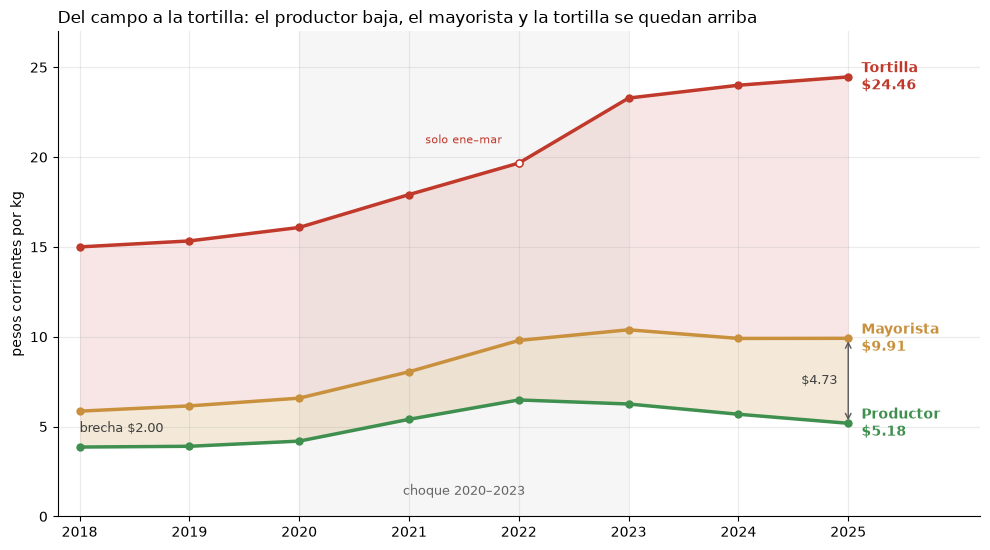

In [4]:
x = cadena["anio"]
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.axvspan(2020, 2023, color="0.5", alpha=0.07, lw=0)
ax.fill_between(x, cadena["productor"], cadena["mayorista"], color=COLORES["mayorista"], alpha=0.2, lw=0)
ax.fill_between(x, cadena["mayorista"], cadena["tortilla"], color=COLORES["tortilla"], alpha=0.12, lw=0)
for e in ESLABONES:
    ax.plot(x, cadena[e], color=COLORES[e], lw=2.5, marker="o", ms=5)
    ax.text(x.iloc[-1] + 0.12, cadena[e].iloc[-1], f"{ETIQUETAS[e]}\n${cadena[e].iloc[-1]:.2f}",
            color=COLORES[e], va="center", fontsize=10, fontweight="bold")
# 2022 de la tortilla solo tiene enero a marzo: marcador hueco
f22 = cadena[cadena["anio"] == 2022].iloc[0]
ax.plot([2022], [f22["tortilla"]], marker="o", ms=5, mfc="white", mec=COLORES["tortilla"], ls="none", zorder=5)
ax.text(2021.85, f22["tortilla"] + 1.1, "solo ene–mar", ha="right", fontsize=8, color=COLORES["tortilla"])
ax.text(2021.5, 1.2, "choque 2020–2023", ha="center", fontsize=9, color="0.4")
a18, a25 = tabla.loc[2018], tabla.loc[2025]
ax.annotate("", xy=(2025, a25["productor"]), xytext=(2025, a25["mayorista"]),
            arrowprops=dict(arrowstyle="<->", color="0.35", lw=1))
ax.text(2024.9, (a25["productor"] + a25["mayorista"]) / 2, f"${a25['dif_mayorista_productor']:.2f}",
        ha="right", va="center", fontsize=9, color="0.25")
ax.text(2018, a18["mayorista"] - 0.55, f"brecha ${a18['dif_mayorista_productor']:.2f}", ha="left",
        va="top", fontsize=9, color="0.25")
ax.set_xlim(2017.8, 2026.2)
ax.set_ylim(0, 27)
ax.set_xticks(range(2018, 2026))
ax.set_ylabel("pesos corrientes por kg")
ax.set_title("Del campo a la tortilla: el productor baja, el mayorista y la tortilla se quedan arriba", loc="left")
fig.tight_layout()
fig.savefig(ruta_figuras / "cadena_abanico.png", dpi=150)
fig.savefig(ruta_figuras / "cadena_abanico.svg")
plt.show()

In [5]:
d18, d25 = tabla.loc[2018], tabla.loc[2025]
md_(
    f"- Brecha mayorista–productor: ${d18['dif_mayorista_productor']:.2f}/kg en 2018 y "
    f"${d25['dif_mayorista_productor']:.2f}/kg en 2025 (x{d25['dif_mayorista_productor'] / d18['dif_mayorista_productor']:.1f}).\n"
    f"- Participación del productor en el precio mayorista: {d18['part_productor_mayorista']:.0f} % (2018), "
    f"{tabla.loc[2022, 'part_productor_mayorista']:.0f} % (2022) y {d25['part_productor_mayorista']:.0f} % (2025).\n"
    f"- Participación del productor en el precio de la tortilla: {d18['part_productor_tortilla']:.0f} % (2018), "
    f"{tabla.loc[2022, 'part_productor_tortilla']:.0f} % (2022) y {d25['part_productor_tortilla']:.0f} % (2025)."
)

- Brecha mayorista–productor: $2.00/kg en 2018 y $4.73/kg en 2025 (x2.4).
- Participación del productor en el precio mayorista: 66 % (2018), 66 % (2022) y 52 % (2025).
- Participación del productor en el precio de la tortilla: 26 % (2018), 33 % (2022) y 21 % (2025).

## 4. El choque y la bajada: transmisión asimétrica por eslabón

Se compara el cambio de cada eslabón en la subida (2020 al pico) con el de la bajada (pico a 2025). El pico se toma en 2022 y en 2023: en 2022 la tortilla solo tiene tres meses de datos, así que 2023 es la lectura más sólida para ese eslabón.

In [6]:
transmision = {pico: transmision_asimetrica(cadena, base=2020, pico=pico, final=2025) for pico in (2022, 2023)}
for pico, t in transmision.items():
    md_(f"**Pico en {pico}** (pesos corrientes por kg; porcentajes sobre el valor de partida de cada fase)")
    display(t.set_index("eslabon").round(2))

**Pico en 2022** (pesos corrientes por kg; porcentajes sobre el valor de partida de cada fase)

,precio_2020,precio_2022,precio_2025,subida_abs,subida_pct,bajada_abs,bajada_pct,pct_subida_revertido
eslabon,,,,,,,,
productor,4.19,6.48,5.18,2.29,54.69,-1.30,-20.04,56.68
mayorista,6.58,9.79,9.91,3.21,48.80,0.12,1.20,-3.66
tortilla,16.08,19.67,24.46,3.58,22.28,4.80,24.39,-133.89


**Pico en 2023** (pesos corrientes por kg; porcentajes sobre el valor de partida de cada fase)

,precio_2020,precio_2023,precio_2025,subida_abs,subida_pct,bajada_abs,bajada_pct,pct_subida_revertido
eslabon,,,,,,,,
productor,4.19,6.26,5.18,2.07,49.31,-1.07,-17.16,51.95
mayorista,6.58,10.39,9.91,3.81,57.81,-0.48,-4.58,12.50
tortilla,16.08,23.29,24.46,7.20,44.78,1.18,5.06,-16.36


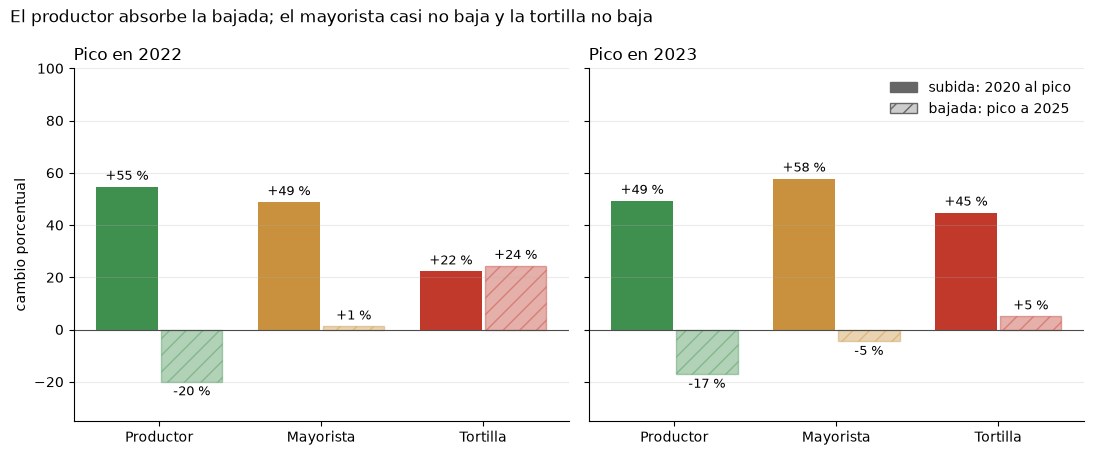

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for eje, (pico, t) in zip(ejes, transmision.items()):
    pos = np.arange(len(t))
    for i, fila in t.iterrows():
        c = COLORES[fila["eslabon"]]
        eje.bar(i - 0.2, fila["subida_pct"], 0.38, color=c)
        eje.bar(i + 0.2, fila["bajada_pct"], 0.38, color=c, alpha=0.4, hatch="//", edgecolor=c)
        for dx, v in ((-0.2, fila["subida_pct"]), (0.2, fila["bajada_pct"])):
            eje.text(i + dx, v + (1.5 if v >= 0 else -1.5), f"{v:+.0f} %", ha="center",
                     va="bottom" if v >= 0 else "top", fontsize=9)
    eje.axhline(0, color="0.3", lw=0.8)
    eje.set_xticks(pos, [ETIQUETAS[e] for e in t["eslabon"]])
    eje.set_title(f"Pico en {pico}", loc="left")
    eje.grid(axis="x", visible=False)
ejes[0].set_ylabel("cambio porcentual")
ejes[0].set_ylim(-35, 100)
ejes[1].legend(handles=[Patch(color="0.4", label="subida: 2020 al pico"),
                        Patch(facecolor="0.8", edgecolor="0.4", hatch="//", label="bajada: pico a 2025")],
               loc="upper right", frameon=False)
fig.suptitle("El productor absorbe la bajada; el mayorista casi no baja y la tortilla no baja", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(ruta_figuras / "cadena_transmision.png", dpi=150)
plt.show()

In [8]:
t22, t23 = transmision[2022].set_index("eslabon"), transmision[2023].set_index("eslabon")
# Comparación con meses homogéneos (enero a marzo de cada año) para la tortilla
tort_nac = tortilla[(tortilla["nivel"] == "nacional") & (tortilla["giro"] == "tortilleria")]
ene_mar = tort_nac[tort_nac["fecha"].dt.month <= 3].groupby(tort_nac["fecha"].dt.year)["precio_mediana_mxn_kg"].mean()
md_(
    f"- Productor: +{t22.loc['productor', 'subida_pct']:.0f} % en la subida (2020–2022) y "
    f"{t22.loc['productor', 'bajada_pct']:.0f} % en la bajada (2022–2025); revierte {t22.loc['productor', 'pct_subida_revertido']:.0f} % de la alza.\n"
    f"- Mayorista: +{t22.loc['mayorista', 'subida_pct']:.0f} % y {t22.loc['mayorista', 'bajada_pct']:+.0f} %; "
    f"con pico en 2023, +{t23.loc['mayorista', 'subida_pct']:.0f} % y {t23.loc['mayorista', 'bajada_pct']:+.0f} % "
    f"(revierte {t23.loc['mayorista', 'pct_subida_revertido']:.0f} % de la alza).\n"
    f"- Tortilla: +{t23.loc['tortilla', 'subida_pct']:.0f} % hasta 2023 y {t23.loc['tortilla', 'bajada_pct']:+.0f} % después. "
    f"Con solo enero–marzo de cada año: ${ene_mar[2020]:.2f} (2020), ${ene_mar[2022]:.2f} (2022), ${ene_mar[2025]:.2f} (2025) por kg."
)

- Productor: +55 % en la subida (2020–2022) y -20 % en la bajada (2022–2025); revierte 57 % de la alza.
- Mayorista: +49 % y +1 %; con pico en 2023, +58 % y -5 % (revierte 13 % de la alza).
- Tortilla: +45 % hasta 2023 y +5 % después. Con solo enero–marzo de cada año: $16.00 (2020), $19.67 (2022), $24.17 (2025) por kg.

## 5. Gruma frente al choque

Resumen de la fase 2 con cifras recalculadas aquí: correlación mensual entre el cambio del precio del maíz de cada central y el rendimiento de Gruma, rendimiento anual en los años del choque y el episodio de la invasión a Ucrania.

In [9]:
g = rend["GRUMAB.MX"].loc["2013":"2025"]
por_mercado = sniim.groupby(["fecha", "mercado"])["precio_mxn_kg"].mean().unstack()
mediana_mensual = por_mercado.median(axis=1)

filas = []
for mercado in por_mercado.columns:
    cambio = por_mercado[mercado] / por_mercado[mercado].shift(1) - 1
    for rezago in range(4):
        d = pd.DataFrame({"g": g, "m": cambio.shift(rezago)}).dropna()
        r = stats.spearmanr(d["g"], d["m"])
        filas.append({"mercado": mercado, "rezago_meses": rezago, "n": len(d), "spearman": r.statistic, "p_valor": r.pvalue})
corr = pd.DataFrame(filas)
corr_mismo_mes = corr[corr["rezago_meses"] == 0].set_index("mercado")
display(corr.pivot(index="mercado", columns="rezago_meses", values="spearman").round(2))

inicio = pd.Timestamp("2022-02-01")
maiz_3m = mediana_mensual.shift(-3)[inicio] / mediana_mensual[inicio] - 1
gruma_3m = (1 + g.loc["2022-03":"2022-05"]).prod() - 1
rend_anual = cadena.set_index("anio")["rendimiento_gruma"]
md_(
    f"- Spearman mes a mes (mismo mes): de {corr_mismo_mes['spearman'].min():.2f} a {corr_mismo_mes['spearman'].max():.2f}; "
    f"con rezagos de 0 a 3 meses, de {corr['spearman'].min():.2f} a {corr['spearman'].max():.2f}; "
    f"el menor p-valor es {corr['p_valor'].min():.2f} entre {len(corr)} pruebas, esperable por azar.\n"
    f"- Rendimiento anual de Gruma: {rend_anual[2020]:+.0%} (2020), {rend_anual[2021]:+.0%} (2021), "
    f"{rend_anual[2022]:+.0%} (2022), {rend_anual[2023]:+.0%} (2023).\n"
    f"- Ucrania (febrero de 2022, tres meses después): maíz mayorista {maiz_3m:+.1%}, Gruma {gruma_3m:+.1%}."
)

rezago_meses,0,1,2,3
mercado,,,,
Culiacán,0.03,-0.17,-0.01,-0.01
Guadalajara,-0.10,-0.03,0.05,-0.10
Guadalupe,0.03,-0.08,0.02,-0.13
Hermosillo,0.13,0.02,-0.18,0.06
Iztapalapa,0.10,-0.15,-0.02,-0.02


- Spearman mes a mes (mismo mes): de -0.10 a 0.13; con rezagos de 0 a 3 meses, de -0.18 a 0.13; el menor p-valor es 0.03 entre 20 pruebas, esperable por azar.
- Rendimiento anual de Gruma: +24% (2020), +13% (2021), +3% (2022), +22% (2023).
- Ucrania (febrero de 2022, tres meses después): maíz mayorista +16.2%, Gruma -15.4%.

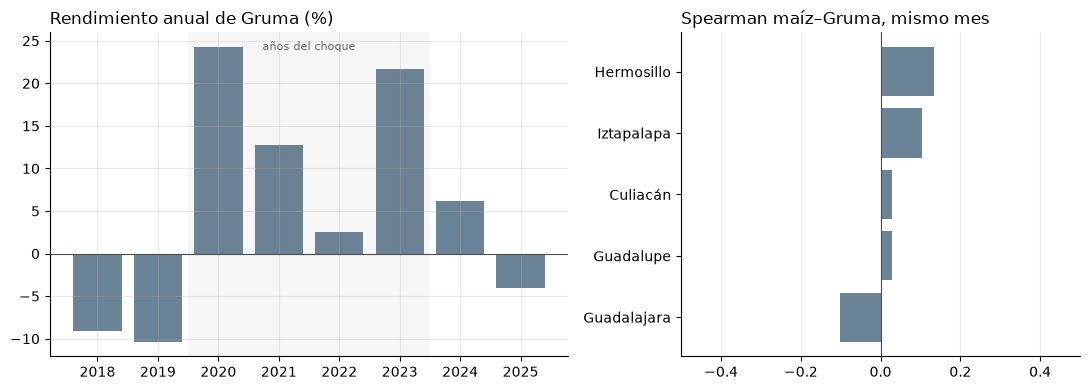

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]})
anios = rend_anual.loc[2018:2025]
ejes[0].bar(anios.index, anios * 100, color=COLORES["gruma"])
ejes[0].axvspan(2019.5, 2023.5, color="0.5", alpha=0.07, lw=0)
ejes[0].axhline(0, color="0.3", lw=0.8)
ejes[0].set_title("Rendimiento anual de Gruma (%)", loc="left")
ejes[0].set_xticks(anios.index)
ejes[0].text(2021.5, ejes[0].get_ylim()[1] * 0.92, "años del choque", ha="center", fontsize=8, color="0.4")
rho = corr_mismo_mes["spearman"].sort_values()
ejes[1].barh(rho.index, rho.values, color=COLORES["gruma"])
ejes[1].axvline(0, color="0.3", lw=0.8)
ejes[1].set_xlim(-0.5, 0.5)
ejes[1].set_title("Spearman maíz–Gruma, mismo mes", loc="left")
ejes[1].grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(ruta_figuras / "cadena_gruma.png", dpi=150)
plt.show()

## 6. Sinaloa y Sonora

Producción y precio rural por estado y ciclo (otoño-invierno, OI; primavera-verano, PV). Sinaloa es el mayor productor de maíz grano; en 2024–2025 la sequía recortó la siembra del ciclo OI.

In [11]:
def por_estado(estado):
    d = maiz[maiz["Nomestado"] == estado]
    ciclo = d.groupby(["Anio", "Nomcicloproductivo"])[["Volumenproduccion", "Valorproduccion"]].sum()
    total = d.groupby("Anio")[["Volumenproduccion", "Valorproduccion"]].sum()
    out = pd.DataFrame({
        "prod_Mt_total": total["Volumenproduccion"] / 1e6,
        "prod_Mt_OI": ciclo.xs("Otoño-Invierno", level=1)["Volumenproduccion"] / 1e6,
        "prod_Mt_PV": ciclo.xs("Primavera-Verano", level=1)["Volumenproduccion"] / 1e6,
        "precio_t_total": total["Valorproduccion"] / total["Volumenproduccion"],
        "precio_t_OI": ciclo.xs("Otoño-Invierno", level=1).eval("Valorproduccion / Volumenproduccion"),
        "precio_t_PV": ciclo.xs("Primavera-Verano", level=1).eval("Valorproduccion / Volumenproduccion"),
    })
    out.index.name = "año"
    return out


estados = {e: por_estado(e) for e in ("Sinaloa", "Sonora")}
nacional = maiz.groupby("Anio")[["Volumenproduccion", "Valorproduccion"]].sum()
prod_nacional = nacional["Volumenproduccion"] / 1e6
for e, t in estados.items():
    md_(f"**{e}** (producción en millones de toneladas; precio rural en $/tonelada)")
    display(t.round(2))

**Sinaloa** (producción en millones de toneladas; precio rural en $/tonelada)

,prod_Mt_total,prod_Mt_OI,prod_Mt_PV,precio_t_total,precio_t_OI,precio_t_PV
año,,,,,,
2018,5.82,5.14,0.68,3855.44,3882.88,3646.48
2019,6.44,6.04,0.40,3651.07,3647.50,3705.23
2020,6.30,5.78,0.52,3699.67,3703.20,3660.28
2021,5.54,5.44,0.10,5943.49,5957.63,5147.63
2022,5.31,5.22,0.09,6749.23,6773.57,5267.72
2023,6.66,6.52,0.13,5693.16,5688.05,5940.40
2024,3.37,3.34,0.03,4572.89,4575.13,4314.47
2025,2.28,2.21,0.06,5807.53,5842.28,4601.81


**Sonora** (producción en millones de toneladas; precio rural en $/tonelada)

,prod_Mt_total,prod_Mt_OI,prod_Mt_PV,precio_t_total,precio_t_OI,precio_t_PV
año,,,,,,
2018,0.55,0.52,0.03,3424.11,3411.39,3659.33
2019,0.69,0.67,0.03,3613.23,3609.88,3700.11
2020,0.63,0.62,0.02,3744.47,3711.76,4983.11
2021,0.79,0.76,0.03,5035.60,5020.47,5437.93
2022,0.19,0.17,0.02,6651.57,6628.82,6880.84
2023,0.50,0.49,0.01,5981.46,5946.71,7396.67
2024,0.17,0.16,0.01,5370.19,5297.77,6558.07
2025,0.12,0.10,0.01,5217.42,5183.05,5507.40


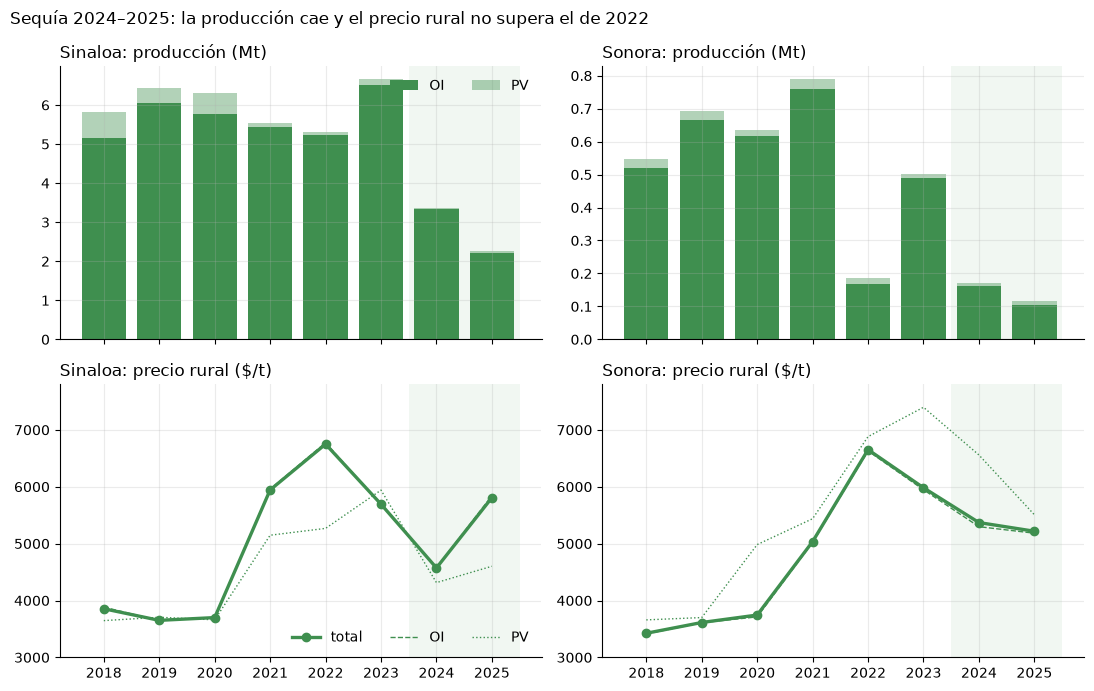

In [12]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for j, (e, t) in enumerate(estados.items()):
    ejes[0, j].bar(t.index, t["prod_Mt_OI"], color=COLORES["productor"], label="OI")
    ejes[0, j].bar(t.index, t["prod_Mt_PV"], bottom=t["prod_Mt_OI"], color=COLORES["productor"], alpha=0.4, label="PV")
    ejes[0, j].set_title(f"{e}: producción (Mt)", loc="left")
    ejes[1, j].plot(t.index, t["precio_t_total"], color=COLORES["productor"], marker="o", lw=2.4, label="total")
    ejes[1, j].plot(t.index, t["precio_t_OI"], color=COLORES["productor"], lw=1, ls="--", label="OI")
    ejes[1, j].plot(t.index, t["precio_t_PV"], color=COLORES["productor"], lw=1, ls=":", label="PV")
    ejes[1, j].set_title(f"{e}: precio rural ($/t)", loc="left")
    ejes[1, j].set_ylim(3000, 7800)
    ejes[1, j].set_xticks(range(2018, 2026))
    for fila in (0, 1):
        ejes[fila, j].axvspan(2023.5, 2025.5, color=COLORES["productor"], alpha=0.07, lw=0)
ejes[0, 0].legend(frameon=False, ncol=2, loc="upper right")
ejes[1, 0].legend(frameon=False, ncol=3, loc="lower right")
fig.suptitle("Sequía 2024–2025: la producción cae y el precio rural no supera el de 2022", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(ruta_figuras / "cadena_sinaloa_sonora.png", dpi=150)
plt.show()

In [13]:
sin, son = estados["Sinaloa"], estados["Sonora"]
md_(
    f"- Sinaloa: {sin.loc[2023, 'prod_Mt_total']:.1f} Mt en 2023 a {sin.loc[2025, 'prod_Mt_total']:.1f} Mt en 2025; "
    f"precio rural de ${sin.loc[2022, 'precio_t_total']:,.0f}/t (2022) a ${sin.loc[2024, 'precio_t_total']:,.0f}/t (2024) y "
    f"${sin.loc[2025, 'precio_t_total']:,.0f}/t (2025). El precio de 2025 sube frente a 2024 pero sigue "
    f"{(1 - sin.loc[2025, 'precio_t_total'] / sin.loc[2022, 'precio_t_total']):.0%} por debajo de 2022.\n"
    f"- Sonora: {son.loc[2023, 'prod_Mt_total']:.2f} Mt en 2023 a {son.loc[2025, 'prod_Mt_total']:.2f} Mt en 2025; "
    f"precio rural de ${son.loc[2022, 'precio_t_total']:,.0f}/t (2022) a ${son.loc[2025, 'precio_t_total']:,.0f}/t (2025). "
    f"Su producción ya había caído en 2022 ({son.loc[2022, 'prod_Mt_total']:.2f} Mt).\n"
    f"- Producción nacional: {prod_nacional[2023]:.1f} Mt (2023) y {prod_nacional[2025]:.1f} Mt (2025)."
)

- Sinaloa: 6.7 Mt en 2023 a 2.3 Mt en 2025; precio rural de $6,749/t (2022) a $4,573/t (2024) y $5,808/t (2025). El precio de 2025 sube frente a 2024 pero sigue 14% por debajo de 2022.
- Sonora: 0.50 Mt en 2023 a 0.12 Mt en 2025; precio rural de $6,652/t (2022) a $5,217/t (2025). Su producción ya había caído en 2022 (0.19 Mt).
- Producción nacional: 27.5 Mt (2023) y 24.4 Mt (2025).

## 7. Verificación del dato de Culiacán

Desde 2022 muchas cotizaciones aparecen exactamente en 10 $/kg. Se mide cuántas hay por central y si la mediana nacional que "no baja de 10" depende de ellas. Se comparan cuatro versiones del precio mayorista: mediana de todas las cotizaciones del año (con y sin Culiacán) y mediana mensual entre centrales promediada en el año (con y sin Culiacán).

In [14]:
cot = sniim.dropna(subset=["precio_mxn_kg"]).assign(
    anio=lambda d: d["fecha"].dt.year, en_10=lambda d: d["precio_mxn_kg"] == 10)
desde22 = cot[cot["anio"] >= 2022]
share = desde22.groupby(["mercado", "anio"])["en_10"].mean().unstack() * 100
share_total = desde22.groupby("mercado")["en_10"].mean() * 100
share.assign(**{"2022–2025": share_total}).round(0)

anio,2022,2023,2024,2025,2022–2025
mercado,,,,,
Culiacán,17.0,75.0,50.0,8.0,38.0
Guadalajara,8.0,8.0,0.0,8.0,6.0
Guadalupe,0.0,8.0,8.0,17.0,8.0
Hermosillo,17.0,0.0,8.0,0.0,6.0
Iztapalapa,8.0,0.0,17.0,8.0,8.0


In [15]:
cadena_sc = cadena_precios_anual(maiz, sniim, tortilla, rend, excluir_mercados=("Culiacán",)).set_index("anio")
comparacion = pd.DataFrame({
    "cotizaciones, 5 centrales": cot.groupby("anio")["precio_mxn_kg"].median(),
    "cotizaciones, sin Culiacán": cot[cot["mercado"] != "Culiacán"].groupby("anio")["precio_mxn_kg"].median(),
    "mediana mensual, 5 centrales": tabla["mayorista"],
    "mediana mensual, sin Culiacán": cadena_sc["mayorista"],
}).loc[2018:2025]
comparacion.index.name = "año"
display(comparacion.round(2))

culi_en_10 = (desde22["en_10"] & (desde22["mercado"] == "Culiacán")).sum() / desde22["en_10"].sum() * 100
meses_en_10 = (mediana_mensual.loc["2022":] == 10).mean() * 100
a, b = comparacion["cotizaciones, 5 centrales"], comparacion["cotizaciones, sin Culiacán"]
c, d = comparacion["mediana mensual, 5 centrales"], comparacion["mediana mensual, sin Culiacán"]
md_(
    f"- Cotizaciones exactamente en 10 $/kg entre 2022 y 2025: Culiacán {share_total['Culiacán']:.0f} %, "
    f"los demás entre {share_total.drop('Culiacán').min():.0f} % y {share_total.drop('Culiacán').max():.0f} %. "
    f"Culiacán aporta {culi_en_10:.0f} % de todas las cotizaciones en 10. Su pico es 2023 ({share.loc['Culiacán', 2023]:.0f} %).\n"
    f"- Mediana de cotizaciones: {a[2022]:.2f}, {a[2023]:.2f}, {a[2024]:.2f} y {a[2025]:.2f} en 2022–2025; "
    f"sin Culiacán, {b[2022]:.2f}, {b[2023]:.2f}, {b[2024]:.2f} y {b[2025]:.2f}.\n"
    f"- Mediana mensual entre centrales: {c[2022]:.2f}, {c[2023]:.2f}, {c[2024]:.2f} y {c[2025]:.2f}; "
    f"sin Culiacán, {d[2022]:.2f}, {d[2023]:.2f}, {d[2024]:.2f} y {d[2025]:.2f}.\n"
    f"- Meses desde 2022 en que la mediana mensual de las cinco centrales es exactamente 10: {meses_en_10:.0f} %."
)

,"cotizaciones, 5 centrales","cotizaciones, sin Culiacán","mediana mensual, 5 centrales","mediana mensual, sin Culiacán"
año,,,,
2018,5.91,6.00,5.86,6.01
2019,6.10,6.39,6.15,6.38
2020,6.32,7.02,6.58,6.95
2021,8.00,8.50,8.05,8.38
2022,10.00,10.13,9.79,10.11
2023,10.04,10.86,10.39,10.69
2024,10.00,10.00,9.91,10.21
2025,10.00,10.41,9.91,10.47


- Cotizaciones exactamente en 10 $/kg entre 2022 y 2025: Culiacán 38 %, los demás entre 6 % y 8 %. Culiacán aporta 56 % de todas las cotizaciones en 10. Su pico es 2023 (75 %).
- Mediana de cotizaciones: 10.00, 10.04, 10.00 y 10.00 en 2022–2025; sin Culiacán, 10.13, 10.87, 10.00 y 10.41.
- Mediana mensual entre centrales: 9.79, 10.39, 9.91 y 9.91; sin Culiacán, 10.11, 10.69, 10.21 y 10.47.
- Meses desde 2022 en que la mediana mensual de las cinco centrales es exactamente 10: 27 %.

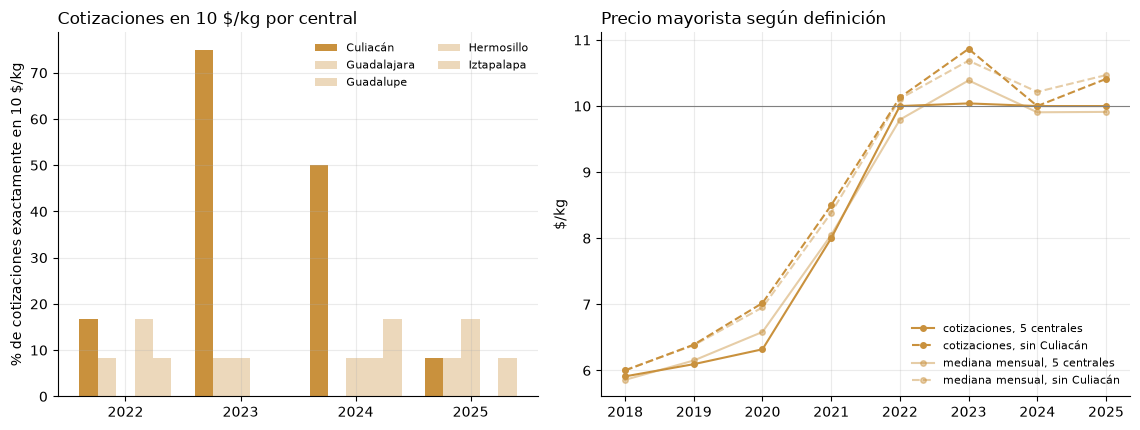

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
anios22 = [2022, 2023, 2024, 2025]
ancho = 0.16
for i, mercado in enumerate(share.index):
    culi = mercado == "Culiacán"
    ejes[0].bar(np.arange(4) + (i - 2) * ancho, share.loc[mercado, anios22], ancho,
                color=COLORES["mayorista"], alpha=1 if culi else 0.35, label=mercado)
ejes[0].set_xticks(range(4), anios22)
ejes[0].set_ylabel("% de cotizaciones exactamente en 10 $/kg")
ejes[0].set_title("Cotizaciones en 10 $/kg por central", loc="left")
ejes[0].legend(frameon=False, fontsize=8, ncol=2)
estilos = [("cotizaciones, 5 centrales", "-", 1.0), ("cotizaciones, sin Culiacán", "--", 1.0),
           ("mediana mensual, 5 centrales", "-", 0.45), ("mediana mensual, sin Culiacán", "--", 0.45)]
for col, ls, alfa in estilos:
    ejes[1].plot(comparacion.index, comparacion[col], color=COLORES["mayorista"], ls=ls, alpha=alfa,
                 marker="o", ms=4, label=col)
ejes[1].axhline(10, color="0.5", lw=0.8)
ejes[1].set_xticks(range(2018, 2026))
ejes[1].set_ylabel("$/kg")
ejes[1].set_title("Precio mayorista según definición", loc="left")
ejes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(ruta_figuras / "cadena_culiacan.png", dpi=150)
plt.show()

In [17]:
t_sc = transmision_asimetrica(cadena_sc.reset_index(), pico=2023).set_index("eslabon")
md_(
    f"Sin Culiacán, el mayorista pasa de ${cadena_sc.loc[2020, 'mayorista']:.2f} (2020) a ${cadena_sc.loc[2023, 'mayorista']:.2f} (2023) "
    f"y ${cadena_sc.loc[2025, 'mayorista']:.2f} (2025): bajada de {t_sc.loc['mayorista', 'bajada_pct']:+.1f} % desde el pico de 2023 "
    f"(con las cinco centrales, {t23.loc['mayorista', 'bajada_pct']:+.1f} %). La participación del productor en 2025 sería "
    f"{cadena_sc.loc[2025, 'part_productor_mayorista']:.0f} % (con las cinco, {tabla.loc[2025, 'part_productor_mayorista']:.0f} %)."
)

Sin Culiacán, el mayorista pasa de $6.95 (2020) a $10.69 (2023) y $10.47 (2025): bajada de -2.0 % desde el pico de 2023 (con las cinco centrales, -4.6 %). La participación del productor en 2025 sería 50 % (con las cinco, 52 %).

## 8. El consumidor: la tortilla subió y no bajó

Precio mensual de la tortilla en tortillerías (PROFECO) frente al maíz mayorista del mismo periodo. Las líneas se cortan donde no hay datos.

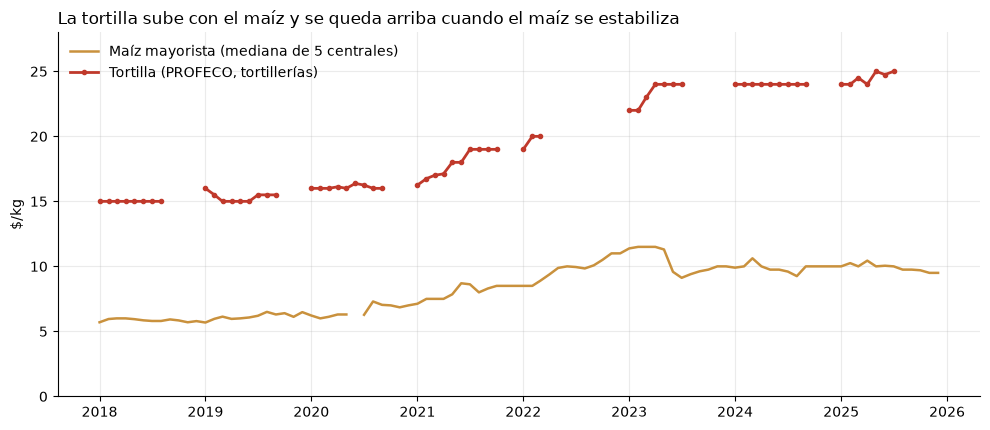

In [18]:
meses = pd.date_range("2018-01-01", "2025-12-01", freq="MS")
tort_mes = tort_nac.set_index("fecha")["precio_mediana_mxn_kg"].reindex(meses)
mayo_mes = mediana_mensual.reindex(meses)

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(meses, mayo_mes, color=COLORES["mayorista"], lw=1.8, label="Maíz mayorista (mediana de 5 centrales)")
ax.plot(meses, tort_mes, color=COLORES["tortilla"], lw=2, marker="o", ms=3, label="Tortilla (PROFECO, tortillerías)")
ax.set_ylabel("$/kg")
ax.set_ylim(0, 28)
ax.legend(frameon=False, loc="upper left")
ax.set_title("La tortilla sube con el maíz y se queda arriba cuando el maíz se estabiliza", loc="left")
fig.tight_layout()
fig.savefig(ruta_figuras / "cadena_tortilla.png", dpi=150)
plt.show()

In [19]:
sal = (pd.read_csv(raiz / "data" / "processed" / "tortilla_salario_anual.csv")
       .query("area == 'general' and giro == 'tortilleria'").set_index("anio")["pct_salario"])
tt = tabla["tortilla"]
n_sin_dato = int(tort_mes.isna().sum())
md_(
    f"- Tortilla: ${tt[2018]:.2f}/kg (2018), ${tt[2020]:.2f} (2020), ${tt[2023]:.2f} (2023), ${tt[2025]:.2f} (2025): "
    f"{tt[2025] / tt[2020] - 1:+.0%} frente a 2020 y {tt[2025] / tt[2023] - 1:+.1%} frente a 2023. "
    f"Años con alza frente al anterior: {int((tt.diff().dropna() > 0).sum())} de {len(tt) - 1}.\n"
    f"- La serie mensual tiene {n_sin_dato} de {len(meses)} meses sin dato, que no se interpolan.\n"
    f"- Contexto: el costo diario de tortilla de un hogar equivale a {sal[2018]:.1f} % del salario mínimo general en 2018 "
    f"y a {sal[2025]:.1f} % en 2025, porque el salario mínimo subió más rápido que la tortilla."
)

- Tortilla: $15.00/kg (2018), $16.08 (2020), $23.29 (2023), $24.46 (2025): +52% frente a 2020 y +5.1% frente a 2023. Años con alza frente al anterior: 7 de 7.
- La serie mensual tiene 34 de 96 meses sin dato, que no se interpolan.
- Contexto: el costo diario de tortilla de un hogar equivale a 8.7 % del salario mínimo general en 2018 y a 4.0 % en 2025, porque el salario mínimo subió más rápido que la tortilla.

## 9. Síntesis

In [20]:
hmo = por_mercado.loc["2022":"2025", "Hermosillo"]
tm = tabla
verif = [
    # concepto, borrador (texto), valor borrador, dato, tolerancia, formato
    ("Mayorista 2020 ($/kg)", "alrededor de 6", 6.0, tm.loc[2020, "mayorista"], 0.3, "{:.2f}"),
    ("Mayorista 2022 ($/kg)", "10", 10.0, tm.loc[2022, "mayorista"], 0.25, "{:.2f}"),
    ("Maíz mayorista tras Ucrania, 3 meses (%)", "+16", 16.0, maiz_3m * 100, 1.0, "{:+.1f}"),
    ("Gruma 2020 (%)", "+24", 24.0, rend_anual[2020] * 100, 1.0, "{:+.1f}"),
    ("Gruma 2021 (%)", "+13", 13.0, rend_anual[2021] * 100, 1.0, "{:+.1f}"),
    ("Gruma 2022 (%)", "+3", 3.0, rend_anual[2022] * 100, 1.0, "{:+.1f}"),
    ("Gruma 2023 (%)", "+22", 22.0, rend_anual[2023] * 100, 1.0, "{:+.1f}"),
    ("Gruma tras Ucrania, 3 meses (%)", "-15", -15.0, gruma_3m * 100, 1.0, "{:+.1f}"),
    ("Spearman mínimo maíz–Gruma", "-0.10", -0.10, corr_mismo_mes["spearman"].min(), 0.02, "{:.2f}"),
    ("Spearman máximo maíz–Gruma", "0.14", 0.14, corr_mismo_mes["spearman"].max(), 0.02, "{:.2f}"),
    ("P-valor mínimo con rezagos de 0 a 3 meses", "mayor que 0.1", 0.1, corr["p_valor"].min(), None, "{:.2f}"),
    ("Productor 2018 ($/kg)", "3.86", 3.86, tm.loc[2018, "productor"], 0.01, "{:.2f}"),
    ("Mayorista 2018 ($/kg)", "5.91", 5.91, tm.loc[2018, "mayorista"], 0.1, "{:.2f}"),
    ("Participación del productor 2018 (%)", "65", 65.0, tm.loc[2018, "part_productor_mayorista"], 1.0, "{:.0f}"),
    ("Productor 2022 ($/kg)", "6.48", 6.48, tm.loc[2022, "productor"], 0.01, "{:.2f}"),
    ("Participación del productor 2022 (%)", "65", 65.0, tm.loc[2022, "part_productor_mayorista"], 1.0, "{:.0f}"),
    ("Productor 2022 a 2025 (%)", "-20", -20.0, (tm.loc[2025, "productor"] / tm.loc[2022, "productor"] - 1) * 100, 0.5, "{:+.1f}"),
    ("Productor 2025 ($/kg)", "5.18", 5.18, tm.loc[2025, "productor"], 0.01, "{:.2f}"),
    ("Mayorista mínimo 2023–2025: no baja de 10 ($/kg)", "10", 10.0, tm.loc[2023:2025, "mayorista"].min(), 0.05, "{:.2f}"),
    ("Hermosillo, máximo mensual 2022–2025 ($/kg)", "13", 13.0, hmo.max(), 0.5, "{:.1f}"),
    ("Participación del productor 2024 (%)", "57", 57.0, tm.loc[2024, "part_productor_mayorista"], 1.0, "{:.0f}"),
    ("Participación del productor 2025 (%)", "52", 52.0, tm.loc[2025, "part_productor_mayorista"], 1.0, "{:.0f}"),
    ("Brecha mayorista–productor 2018 ($/kg)", "2", 2.0, tm.loc[2018, "dif_mayorista_productor"], 0.1, "{:.2f}"),
    ("Brecha mayorista–productor 2025 ($/kg)", "casi 5", 5.0, tm.loc[2025, "dif_mayorista_productor"], 0.3, "{:.2f}"),
    ("Brecha 2025 / brecha 2018", "2.4", 2.4, tm.loc[2025, "dif_mayorista_productor"] / tm.loc[2018, "dif_mayorista_productor"], 0.1, "{:.1f}"),
    ("Sinaloa, producción 2023 (Mt)", "6.7", 6.7, sin.loc[2023, "prod_Mt_total"], 0.1, "{:.1f}"),
    ("Sinaloa, producción 2025 (Mt)", "2.3", 2.3, sin.loc[2025, "prod_Mt_total"], 0.1, "{:.1f}"),
    ("Producción nacional 2023 (Mt)", "27", 27.0, prod_nacional[2023], 1.0, "{:.1f}"),
    ("Producción nacional 2025 (Mt)", "24", 24.0, prod_nacional[2025], 1.0, "{:.1f}"),
    ("Sinaloa, precio rural 2022 ($/t)", "6 749", 6749.0, sin.loc[2022, "precio_t_total"], 5.0, "{:,.0f}"),
    ("Sinaloa, precio rural 2025 ($/t)", "5 808", 5808.0, sin.loc[2025, "precio_t_total"], 5.0, "{:,.0f}"),
    ("Sinaloa, precio rural 2024 a 2025: 'siguió bajando' (%)", "baja", -1.0, (sin.loc[2025, "precio_t_total"] / sin.loc[2024, "precio_t_total"] - 1) * 100, None, "{:+.1f}"),
]
lineas = ["| Concepto | Borrador dice | Dato | Resultado |", "|---|---|---|---|"]
for concepto, texto, valor, dato, tol, formato in verif:
    if concepto.startswith("P-valor"):
        ok = dato > valor
    else:
        ok = dato < 0 if tol is None else abs(dato - valor) <= tol
    lineas.append(f"| {concepto} | {texto} | {formato.format(dato)} | {'confirma' if ok else 'corrige'} |")
lineas.append(f"| Tortilla por kilo, 2018–2025 | pendiente | ${tm.loc[2018, 'tortilla']:.2f} a ${tm.loc[2025, 'tortilla']:.2f} | completa |")
md_("\n".join(lineas))

| Concepto | Borrador dice | Dato | Resultado |
|---|---|---|---|
| Mayorista 2020 ($/kg) | alrededor de 6 | 6.58 | corrige |
| Mayorista 2022 ($/kg) | 10 | 9.79 | confirma |
| Maíz mayorista tras Ucrania, 3 meses (%) | +16 | +16.2 | confirma |
| Gruma 2020 (%) | +24 | +24.3 | confirma |
| Gruma 2021 (%) | +13 | +12.7 | confirma |
| Gruma 2022 (%) | +3 | +2.6 | confirma |
| Gruma 2023 (%) | +22 | +21.7 | confirma |
| Gruma tras Ucrania, 3 meses (%) | -15 | -15.4 | confirma |
| Spearman mínimo maíz–Gruma | -0.10 | -0.10 | confirma |
| Spearman máximo maíz–Gruma | 0.14 | 0.13 | confirma |
| P-valor mínimo con rezagos de 0 a 3 meses | mayor que 0.1 | 0.03 | corrige |
| Productor 2018 ($/kg) | 3.86 | 3.86 | confirma |
| Mayorista 2018 ($/kg) | 5.91 | 5.86 | confirma |
| Participación del productor 2018 (%) | 65 | 66 | confirma |
| Productor 2022 ($/kg) | 6.48 | 6.48 | confirma |
| Participación del productor 2022 (%) | 65 | 66 | corrige |
| Productor 2022 a 2025 (%) | -20 | -20.0 | confirma |
| Productor 2025 ($/kg) | 5.18 | 5.18 | confirma |
| Mayorista mínimo 2023–2025: no baja de 10 ($/kg) | 10 | 9.91 | corrige |
| Hermosillo, máximo mensual 2022–2025 ($/kg) | 13 | 13.0 | confirma |
| Participación del productor 2024 (%) | 57 | 57 | confirma |
| Participación del productor 2025 (%) | 52 | 52 | confirma |
| Brecha mayorista–productor 2018 ($/kg) | 2 | 2.00 | confirma |
| Brecha mayorista–productor 2025 ($/kg) | casi 5 | 4.73 | confirma |
| Brecha 2025 / brecha 2018 | 2.4 | 2.4 | confirma |
| Sinaloa, producción 2023 (Mt) | 6.7 | 6.7 | confirma |
| Sinaloa, producción 2025 (Mt) | 2.3 | 2.3 | confirma |
| Producción nacional 2023 (Mt) | 27 | 27.5 | confirma |
| Producción nacional 2025 (Mt) | 24 | 24.4 | confirma |
| Sinaloa, precio rural 2022 ($/t) | 6 749 | 6,749 | confirma |
| Sinaloa, precio rural 2025 ($/t) | 5 808 | 5,808 | confirma |
| Sinaloa, precio rural 2024 a 2025: 'siguió bajando' (%) | baja | +27.0 | corrige |
| Tortilla por kilo, 2018–2025 | pendiente | $15.00 a $24.46 | completa |

In [21]:
t22p, t23p = t22.loc["productor"], t23.loc["productor"]
md_(
    "**Hallazgos**\n\n"
    f"1. **El choque fue general.** De 2020 a 2022 el productor subió {t22p['subida_pct']:.0f} % y el mayorista "
    f"{t22.loc['mayorista', 'subida_pct']:.0f} %; la tortilla subió {t23.loc['tortilla', 'subida_pct']:.0f} % hasta 2023 (2022 tiene pocos meses). "
    f"La participación del productor se mantuvo en {tm.loc[2020:2022, 'part_productor_mayorista'].min():.0f}–"
    f"{tm.loc[2020:2022, 'part_productor_mayorista'].max():.0f} % del mayorista.\n"
    f"2. **La bajada llegó al campo, no más arriba.** De 2022 a 2025 el productor cayó {abs(t22p['bajada_pct']):.0f} % "
    f"(${t22p['precio_2022']:.2f} a ${t22p['precio_2025']:.2f}/kg); el mayorista cambió {t22.loc['mayorista', 'bajada_pct']:+.1f} % "
    f"(o {t23.loc['mayorista', 'bajada_pct']:+.1f} % desde su pico de 2023) y la tortilla {t23.loc['tortilla', 'bajada_pct']:+.1f} % desde 2023.\n"
    f"3. **La brecha se amplió.** La diferencia mayorista–productor pasó de ${tm.loc[2018, 'dif_mayorista_productor']:.2f} a "
    f"${tm.loc[2025, 'dif_mayorista_productor']:.2f}/kg y la participación del productor, de {tm.loc[2018, 'part_productor_mayorista']:.0f} % a "
    f"{tm.loc[2025, 'part_productor_mayorista']:.0f} % del mayorista y de {tm.loc[2018, 'part_productor_tortilla']:.0f} % a "
    f"{tm.loc[2025, 'part_productor_tortilla']:.0f} % del precio de la tortilla. Incluye flete, acopio y margen, no solo ganancia.\n"
    f"4. **Gruma no resintió el choque en bolsa.** Correlaciones mensuales (rezagos de 0 a 3 meses) entre {corr['spearman'].min():.2f} y {corr['spearman'].max():.2f}, "
    f"rendimientos de {rend_anual[2020]:+.0%}, {rend_anual[2021]:+.0%}, {rend_anual[2022]:+.0%} y {rend_anual[2023]:+.0%} en 2020–2023; "
    f"solo Ucrania mueve ambas series (maíz {maiz_3m:+.0%}, Gruma {gruma_3m:+.0%} en tres meses).\n"
    f"5. **La sequía no encareció el maíz.** En Sinaloa la producción pasó de {sin.loc[2023, 'prod_Mt_total']:.1f} a "
    f"{sin.loc[2025, 'prod_Mt_total']:.1f} Mt y el precio rural fue ${sin.loc[2024, 'precio_t_total']:,.0f}/t en 2024 y "
    f"${sin.loc[2025, 'precio_t_total']:,.0f}/t en 2025, por debajo de los ${sin.loc[2022, 'precio_t_total']:,.0f}/t de 2022.\n"
    f"6. **Culiacán aplana la mediana de cotizaciones en 10, pero quitarlo no la baja.** "
    f"{share.loc['Culiacán', 2023]:.0f} % de sus cotizaciones de 2023 están en 10 $/kg: la mediana de cotizaciones de ese año es {a[2023]:.2f} con las cinco centrales "
    f"y {b[2023]:.2f} sin Culiacán ({b[2025]:.2f} frente a {a[2025]:.2f} en 2025). Sin Culiacán, la bajada del mayorista desde 2023 es "
    f"{t_sc.loc['mayorista', 'bajada_pct']:+.1f} % (con las cinco, {t23.loc['mayorista', 'bajada_pct']:+.1f} %): el mayorista bajó aún menos.\n"
    f"7. **El consumidor pagó la alza y no recibió la baja.** La tortilla pasó de ${tt[2020]:.2f} a ${tt[2025]:.2f}/kg entre 2020 y 2025; "
    f"el salario mínimo creció más, así que el gasto de tortilla bajó de {sal[2018]:.1f} % a {sal[2025]:.1f} % del salario mínimo."
)

**Hallazgos**

1. **El choque fue general.** De 2020 a 2022 el productor subió 55 % y el mayorista 49 %; la tortilla subió 45 % hasta 2023 (2022 tiene pocos meses). La participación del productor se mantuvo en 64–67 % del mayorista.
2. **La bajada llegó al campo, no más arriba.** De 2022 a 2025 el productor cayó 20 % ($6.48 a $5.18/kg); el mayorista cambió +1.2 % (o -4.6 % desde su pico de 2023) y la tortilla +5.1 % desde 2023.
3. **La brecha se amplió.** La diferencia mayorista–productor pasó de $2.00 a $4.73/kg y la participación del productor, de 66 % a 52 % del mayorista y de 26 % a 21 % del precio de la tortilla. Incluye flete, acopio y margen, no solo ganancia.
4. **Gruma no resintió el choque en bolsa.** Correlaciones mensuales (rezagos de 0 a 3 meses) entre -0.18 y 0.13, rendimientos de +24%, +13%, +3% y +22% en 2020–2023; solo Ucrania mueve ambas series (maíz +16%, Gruma -15% en tres meses).
5. **La sequía no encareció el maíz.** En Sinaloa la producción pasó de 6.7 a 2.3 Mt y el precio rural fue $4,573/t en 2024 y $5,808/t en 2025, por debajo de los $6,749/t de 2022.
6. **Culiacán aplana la mediana de cotizaciones en 10, pero quitarlo no la baja.** 75 % de sus cotizaciones de 2023 están en 10 $/kg: la mediana de cotizaciones de ese año es 10.04 con las cinco centrales y 10.87 sin Culiacán (10.41 frente a 10.00 en 2025). Sin Culiacán, la bajada del mayorista desde 2023 es -2.0 % (con las cinco, -4.6 %): el mayorista bajó aún menos.
7. **El consumidor pagó la alza y no recibió la baja.** La tortilla pasó de $16.08 a $24.46/kg entre 2020 y 2025; el salario mínimo creció más, así que el gasto de tortilla bajó de 8.7 % a 4.0 % del salario mínimo.

In [22]:
salida = tabla.assign(
    mayorista_sin_culiacan=cadena_sc["mayorista"],
    part_productor_mayorista_sin_culiacan=cadena_sc["part_productor_mayorista"],
).reset_index()
salida.to_csv(raiz / "data" / "processed" / "cadena_maiz_anual.csv", index=False)
print(f"Guardado data/processed/cadena_maiz_anual.csv ({len(salida)} filas)")

Guardado data/processed/cadena_maiz_anual.csv (8 filas)
